In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
import pandas as pd

m = 2 #mitral count
x = jnp.ones(m) #OSN input


In [2]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

## 1. Fixing Hill exponents from Elisa

Fit n and scale per cell class from Elisa's firing rate curves `n_r, n_b, n_g, n_y` 
(firing rates vs injected current)

Fit data to Naka Rushton

# Mitral cells

In [3]:
df_mitral_occluded = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - fig 4 ephys.xlsx',
    sheet_name='repetitive firing',
    index_col=0,
    skiprows=3,
    usecols='A,AG:BE',
    nrows=45
)
df_mitral_occluded

,Cell 3.4,Cell 2,Cell 1.2,Cell 5.2,Cell 4.2,Cell 3.5,Cell 1.3,Cell 7.1,Cell 6.2,Cell 5.3,...,Cell4,Cell 5.4,Cell 2.2,Cell 4.4,Cell B_av,Cell_D,Cell 9.1,Cell 11,Cell 3.8,Cell 6.3
bin,,,,,,,,,,,,,,,,,,,,,
0,0,0.000000,0,0,0,0.0,0.0,0,0.000000,0,...,0.0,0,0.0,0.0,0.000000,0.0,0.0,0.0,NaN,0
10,0,0.000000,0,0,0,0.0,0.0,0,0.000000,0,...,0.0,0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0
20,0,0.000000,0,0,0,0.0,0.0,0,0.000000,0,...,0.0,0,5.0,0.0,0.000000,0.0,1.5,0.0,0.0,0
30,0,0.000000,0,0,2,0.0,0.0,0,0.000000,0,...,0.0,0,7.0,0.0,0.000000,0.0,2.5,0.0,0.0,0
40,0,0.000000,0,0,4,0.0,0.0,0,0.000000,0,...,0.0,0,8.0,3.0,0.000000,0.0,4.0,0.0,0.0,0
50,0,0.000000,0,0,7,0.0,0.0,0,0.000000,0,...,0.0,0,9.5,6.0,0.000000,0.0,6.0,0.0,0.0,0
60,0,0.000000,0,0,10,0.0,2.5,0,0.000000,0,...,0.0,0,12.0,7.0,0.000000,0.0,8.0,0.0,0.0,0
70,0,0.000000,0,0,14,1.0,4.5,0,0.000000,0,...,0.0,0,13.5,16.0,0.000000,0.0,9.0,0.0,0.0,0
80,0,0.000000,0,0,18,0.0,4.0,0,0.666667,0,...,0.0,0,16.0,17.0,0.000000,0.0,10.5,0.0,0.0,0


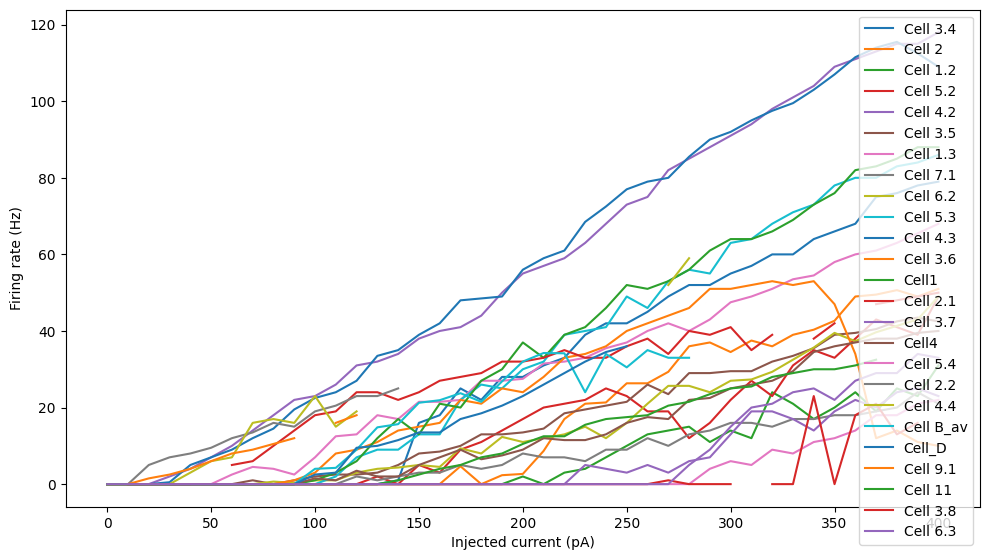

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
df_mitral_occluded.plot(ax=ax, legend=True)
ax.set_xlabel('Injected current (pA)')
ax.set_ylabel('Firing rate (Hz)')
plt.tight_layout()
plt.show()

n =  2.0687982258044033
b =  449.8735974166727


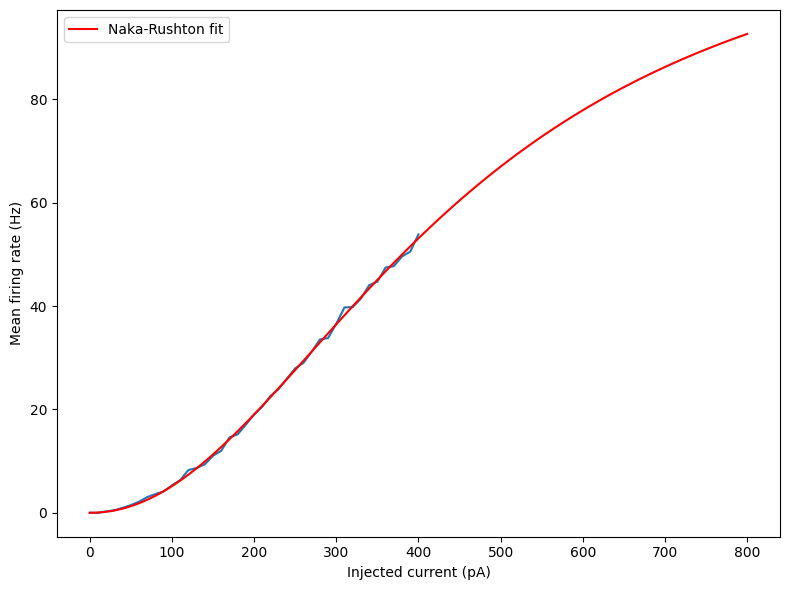

In [6]:
df_plot = df_mitral_occluded
x = np.asarray(df_plot.index, dtype=float)
y = np.asarray(df_plot.mean(axis=1), dtype=float)

def nr_full(x, n, b, y_max):
    x = x / b
    return nr(x, n) * y_max

fit_params, _ = curve_fit(nr_full, x, y, p0=[3, 200, 100])
print("n = ", fit_params[0])
print("b = ", fit_params[1])
ax = df_plot.mean(axis=1).plot(figsize=(8, 6))
ax.set_xlabel('Injected current (pA)')
ax.set_ylabel('Mean firing rate (Hz)')

# plot fit
x_fit = np.linspace(x.min(), 2*x.max(), 100)
y_fit = nr_full(x_fit, *fit_params)
ax.plot(x_fit, y_fit, 'r-', label='Naka-Rushton fit')
ax.legend()
plt.tight_layout()
plt.show()


# Red cells (ETCs)

In [7]:
df_red_occluded = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - fig 5 ephys.xlsx',
    sheet_name='ETC repetitive firing',
    index_col=0,
    skiprows=41,
    usecols='J,N:AQ',
    nrows=73
).dropna(how='all').astype(float)
df_red_occluded

,20160407A,20160407B,20160407C,20160407E,20160407H,20160405A,20160405C,20160405E,20160405G,20160405H,...,20160302D,20160412A,20160412B,20160412C,20160412E,20160412F,20160412G,20160412H,20160412I,20160413A
Bin Centre,,,,,,,,,,,,,,,,,,,,,
5.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,NaN,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.5000,0.0,1.0
15.0,NaN,0.0,0.0,0.0000,5.0,0.0,0.0,0.0,1.0,0.0,...,0.0,NaN,0.0,0.0,0.0,0.0,6.0,8.0000,24.0,6.0
25.0,2.0,0.0,0.0,0.0000,8.0,0.0,0.0,0.0,4.0,0.0,...,0.0,0.0,1.5,0.0,0.0,0.0,19.5,17.0000,30.0,11.5
35.0,NaN,1.0,0.0,5.0000,14.0,0.0,9.0,9.0,7.0,0.0,...,0.0,0.0,0.0,0.0,4.5,19.0,29.0,25.6667,NaN,NaN
45.0,30.0,3.0,0.0,0.0000,20.0,0.0,NaN,7.5,12.0,2.5,...,0.0,0.0,8.5,4.0,3.5,10.5,30.0,31.0000,41.0,21.0
55.0,42.0,6.0,0.0,7.3333,NaN,0.0,NaN,8.5,18.0,5.0,...,0.0,0.0,13.5,6.0,11.0,12.0,36.5,35.0000,NaN,30.0
65.0,47.0,8.0,0.0,12.0000,NaN,0.0,NaN,14.0,22.0,8.0,...,0.0,0.0,16.5,7.0,NaN,19.0,42.0,39.0000,52.0,38.0
75.0,52.0,NaN,15.0,9.0000,NaN,1.0,NaN,13.0,NaN,12.0,...,0.0,0.0,21.5,13.0,24.0,21.0,NaN,42.5000,54.0,38.5
85.0,NaN,20.0,0.0,3.0000,NaN,NaN,NaN,15.0,NaN,15.5,...,0.0,0.0,24.5,14.0,25.0,25.0,53.0,47.0000,57.0,43.5


n =  2.5618893335170405
b =  78.280133173584


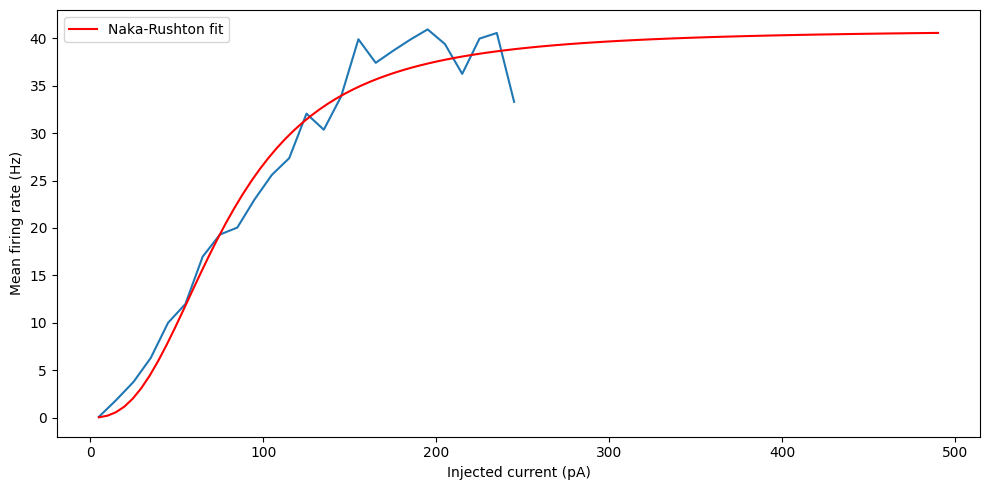

In [8]:
df_plot = df_red_occluded.iloc[:-5]
x = np.asarray(df_plot.index, dtype=float)
y = np.asarray(df_plot.mean(axis=1), dtype=float)

def nr_full(x, n, b):
    x = x / b
    return nr(x, n) * y.max()

fit_params, _ = curve_fit(nr_full, x, y, p0=[3, 200])
print("n = ", fit_params[0])
print("b = ", fit_params[1])
ax = df_plot.mean(axis=1).plot(figsize=(10, 5))
ax.set_xlabel('Injected current (pA)')
ax.set_ylabel('Mean firing rate (Hz)')

# plot fit
x_fit = np.linspace(x.min(), 2*x.max(), 100)
y_fit = nr_full(x_fit, *fit_params)
ax.plot(x_fit, y_fit, 'r-', label='Naka-Rushton fit')
ax.legend()
plt.tight_layout()
plt.show()

# Green cells

In [9]:
df_green_occluded = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - DA cells ephys repetitive firing.xlsx',
    sheet_name='DA cells (Fig 7 and 8)',
    index_col=0,
    skiprows=4,
    usecols='A,Y:AH',
    nrows=51
).dropna(how='all').astype(float)
df_green_occluded

,A.6,D.2,D.3,A.7,D.4,E,B.7,B.8,B.9,C.4
pA,,,,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
10,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0
12,0.0,1.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0
14,0.0,1.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0
16,0.0,1.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,2.0


In [10]:
df_plot = df_green_occluded.drop(columns=['B.4', 'D.1'])
x = np.asarray(df_plot.index, dtype=float)
y = np.asarray(df_plot.mean(axis=1), dtype=float)

def nr_full(x, n, b):
    x = x / b
    return nr(x, n) * y.max() * 1.3

fit_params, _ = curve_fit(nr_full, x, y, p0=[3, 200])

print("n = ", fit_params[0])
print("b = ", fit_params[1])
ax = df_plot.mean(axis=1).plot(figsize=(10, 5))
ax.set_xlabel('Injected current (pA)')
ax.set_ylabel('Mean firing rate (Hz)')
# plot fit
x_fit = np.linspace(x.min(), 2*x.max(), 100)
y_fit = nr_full(x_fit, *fit_params)
ax.plot(x_fit, y_fit, 'r-', label='Naka-Rushton fit')
ax.legend()
plt.tight_layout()
plt.show()

KeyError: "['B.4', 'D.1'] not found in axis"

# Blue cells

In [10]:
df_blue_unperturbed = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - DA cells ephys repetitive firing.xlsx',
    sheet_name='DA cells (Fig 7 and 8)',
    index_col=0,
    skiprows=4,
    usecols='A,N:V',
    nrows=51
).dropna(how='all').astype(float)
df_blue_unperturbed

,A,B.6,C.2,A.1,A.2,C.3,A.3,A.4,A.5
pA,,,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0
6,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,3.0
8,0.0,2.0,0.0,0.0,0.0,2.0,4.0,0.0,5.0
10,0.0,4.0,0.0,1.0,0.0,2.0,5.0,0.0,8.0
12,0.0,3.0,2.0,1.0,0.0,3.0,5.0,0.0,10.0
14,0.0,4.0,2.0,3.0,0.0,4.0,9.0,0.0,11.0
16,1.0,4.0,2.0,3.0,0.0,4.0,10.0,0.0,14.0


Plot data:


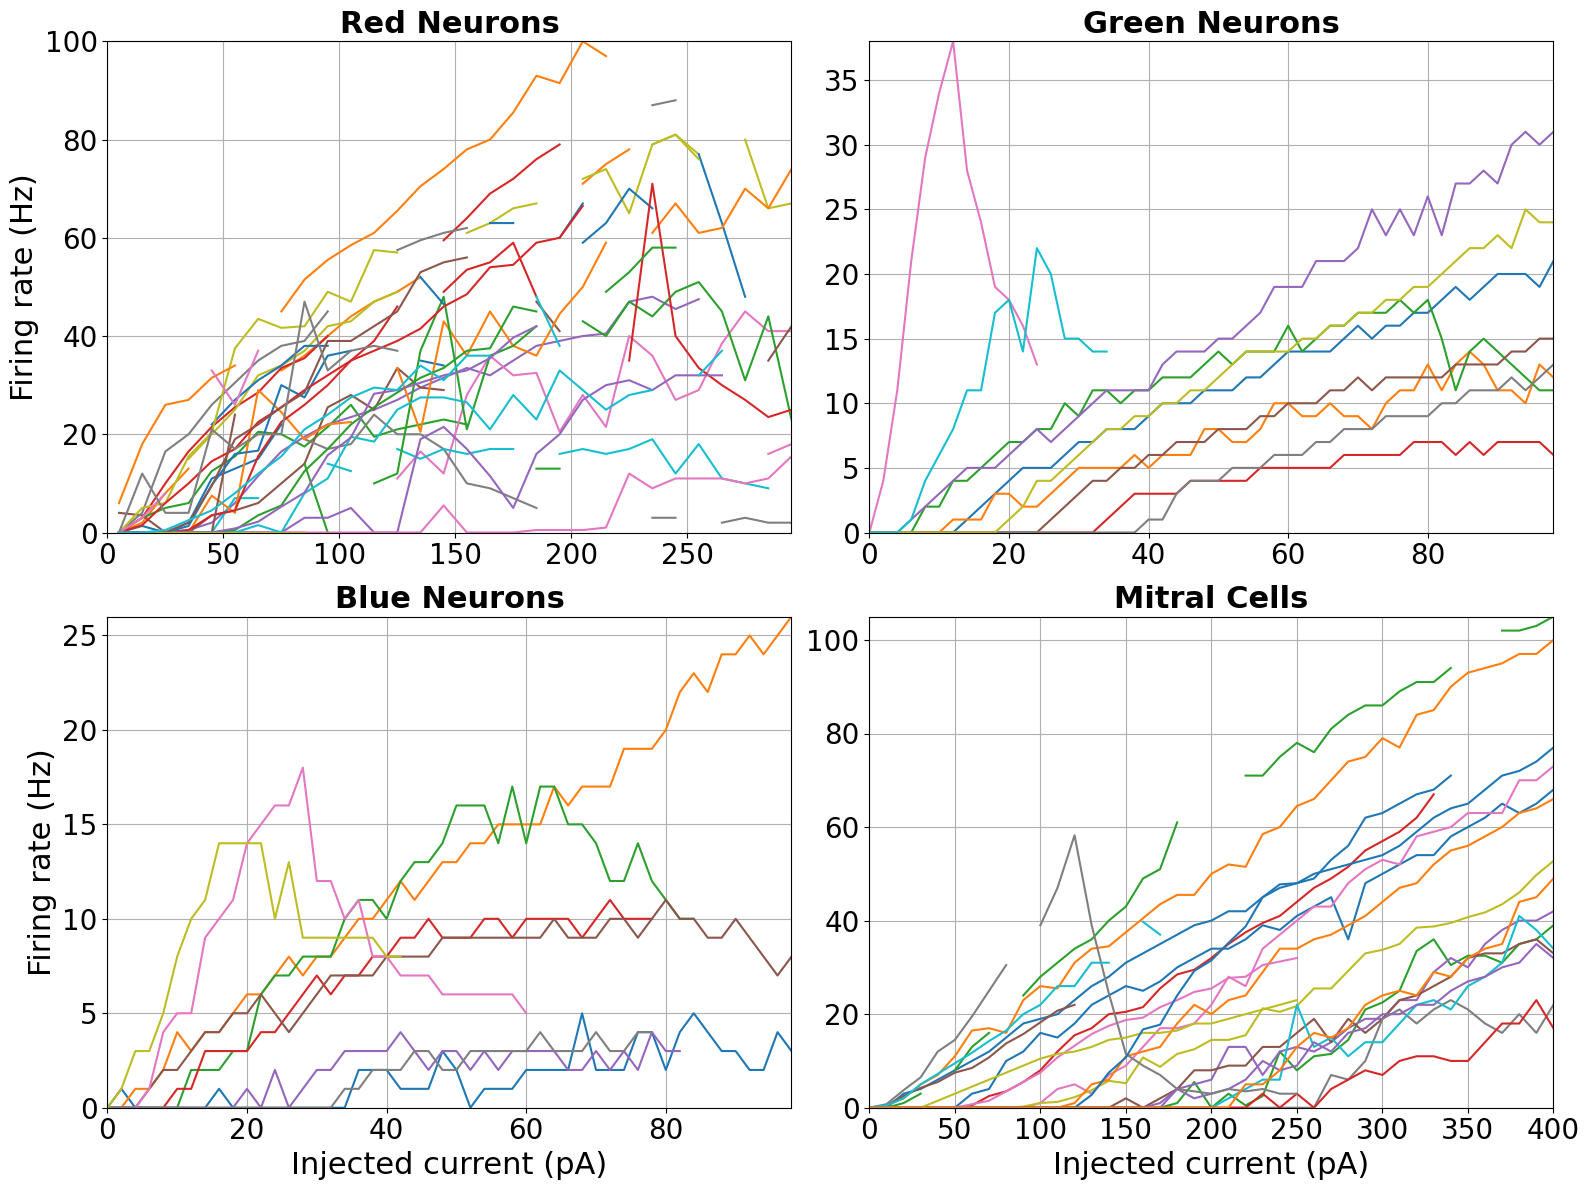

In [11]:

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

datasets = [
    (df_red_unperturbed, axes[0, 0], 'Red Neurons'),
    (df_green_unperturbed, axes[0, 1], 'Green Neurons'),
    (df_blue_unperturbed, axes[1, 0], 'Blue Neurons'),
    (df_mitral_unperturbed, axes[1, 1], 'Mitral Cells')
]

for df, ax, title in datasets:
    df.plot(ax=ax, legend=False)
    ax.set_title(title, fontsize=22, fontweight='bold')
    ax.set_xlim(0, df.index.max())
    ax.set_ylim(0, df.max().max())
    ax.tick_params(axis='both', labelsize=20)
    
axes[0, 0].set_xlabel('')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('')
axes[1, 1].set_ylabel('')

axes[0, 0].set_ylabel('Firing rate (Hz)', fontsize=22)
axes[1, 0].set_ylabel('Firing rate (Hz)', fontsize=22)

axes[1, 0].set_xlabel('Injected current (pA)', fontsize=22)
axes[1, 1].set_xlabel('Injected current (pA)', fontsize=22)
axes[0, 0].grid(True)
axes[0, 1].grid(True)
axes[1, 0].grid(True)
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig(f'Figures_final/all_cells_unperturbed.eps')
plt.show()



Red Neurons
n = 1.850, b = 106.943, y_max = 57.269

Green Neurons
n = 1.868, b = 63.855, y_max = 24.256

Blue Neurons
n = 0.650, b = 38880.228, y_max = 579.160

Mitral Cells
n = 1.560, b = 1403.392, y_max = 444.193


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


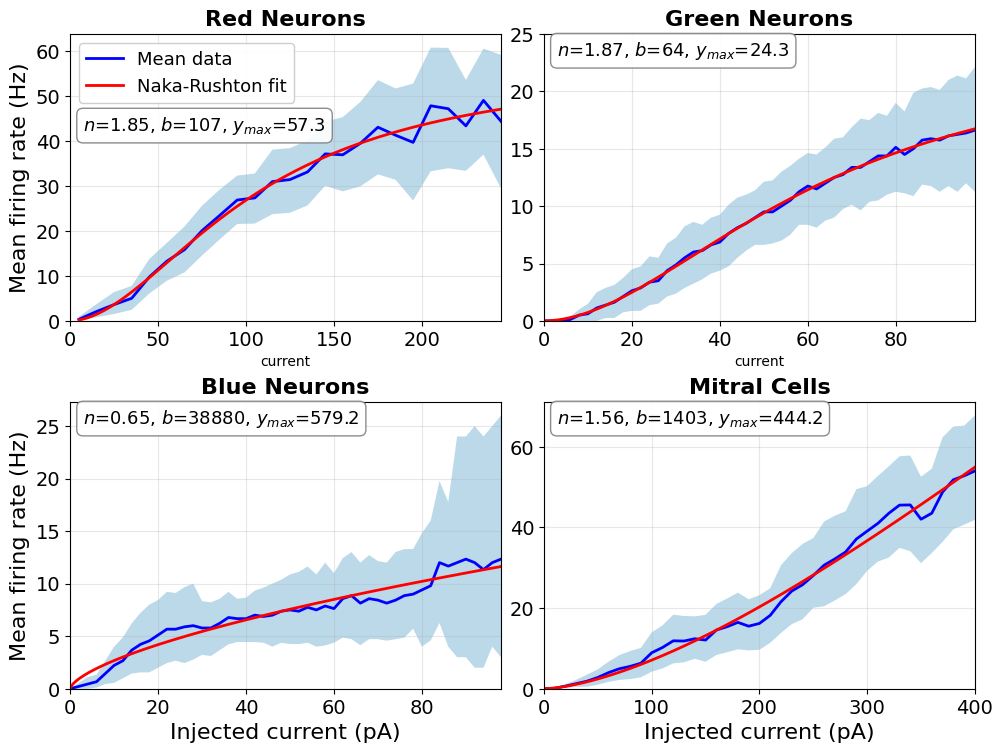

In [12]:
FS_TITLE, FS_LABEL, FS_TICK, FS_LEG, FS_PARAM = 16, 16, 14, 13, 13
param_bbox = dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor='gray', alpha=0.9)

def nr_full(x, n, b, y_max):
    return nr(x / b, n) * y_max

fig, axes = plt.subplots(2, 2, figsize=(10, 7.5), sharex=False)
dfs = [
    df_red_unperturbed.iloc[:-5],
    df_green_unperturbed.drop(columns=['B.4', 'D.1']),
    df_blue_unperturbed,
    df_mitral_unperturbed,
]
titles = ['Red Neurons', 'Green Neurons', 'Blue Neurons', 'Mitral Cells']

for i, (df_plot, title) in enumerate(zip(dfs, titles)):
    ax = axes.flat[i]
    x = np.asarray(df_plot.index, dtype=float)
    y = np.asarray(df_plot.mean(axis=1), dtype=float)
    fit_params, _ = curve_fit(nr_full, x, y, p0=[3, 200, 100], maxfev=8000)

    print(f"\n{title}")
    print(f"n = {fit_params[0]:.3f}, b = {fit_params[1]:.3f}, y_max = {fit_params[2]:.3f}")

    x_fit = np.linspace(x.min(), x.max(), 300)
    y_fit = nr_full(x_fit, *fit_params)

    df_long = (
        df_plot.reset_index(names='current')
        .melt(id_vars='current', var_name='cell', value_name='firing_rate')
    )
    sns.lineplot(
        data=df_long, x='current', y='firing_rate', ax=ax,
        color='blue', linewidth=2, errorbar=('ci', 95), err_style='band',
        err_kws=dict(facecolor='#9ecae1', alpha=0.7, edgecolor='none'),
        label='Mean data' if i == 0 else None, legend=False,
    )
    ax.plot(
        x_fit, y_fit, color='red', linewidth=2,
        label='Naka-Rushton fit' if i == 0 else '_nolegend_',
    )
    ax.set_title(title, fontsize=FS_TITLE, fontweight='bold')
    ax.set_xlim(0, x.max())
    y_upper = max(ax.dataLim.ymax, y_fit.max()) * 1.05
    if i == 1:
        y_upper = np.ceil(y_upper / 5) * 5
        ax.set_yticks(np.arange(0, y_upper + 1, 5))
    ax.set_ylim(0, y_upper)
    ax.tick_params(axis='both', labelsize=FS_TICK)
    ax.grid(True, alpha=0.3)

    param_text = (
        f'$n$={fit_params[0]:.2f}, $b$={fit_params[1]:.0f}, '
        f'$y_{{max}}$={fit_params[2]:.1f}'
    )
    if i == 0:
        leg = ax.legend(loc='upper left', fontsize=FS_LEG, framealpha=0.95)
        fig.canvas.draw()
        param_y = leg.get_window_extent().transformed(ax.transAxes.inverted()).y0 - 0.02
    else:
        param_y = 0.98
    ax.text(
        0.03, param_y, param_text, transform=ax.transAxes,
        fontsize=FS_PARAM, va='top', ha='left', bbox=param_bbox,
    )

axes[0, 0].set_ylabel('Mean firing rate (Hz)', fontsize=FS_LABEL)
axes[1, 0].set_ylabel('Mean firing rate (Hz)', fontsize=FS_LABEL)
axes[1, 0].set_xlabel('Injected current (pA)', fontsize=FS_LABEL)
axes[1, 1].set_xlabel('Injected current (pA)', fontsize=FS_LABEL)
axes[0, 1].set_ylabel('')
axes[1, 1].set_ylabel('')
plt.tight_layout(pad=0.6)
plt.savefig('Figures_final/n_fit_all_cells.eps', bbox_inches='tight')
plt.show()

In [13]:
n_r = 1.85
n_g = 1.87
n_b = 0.65
n_y = 1.56

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


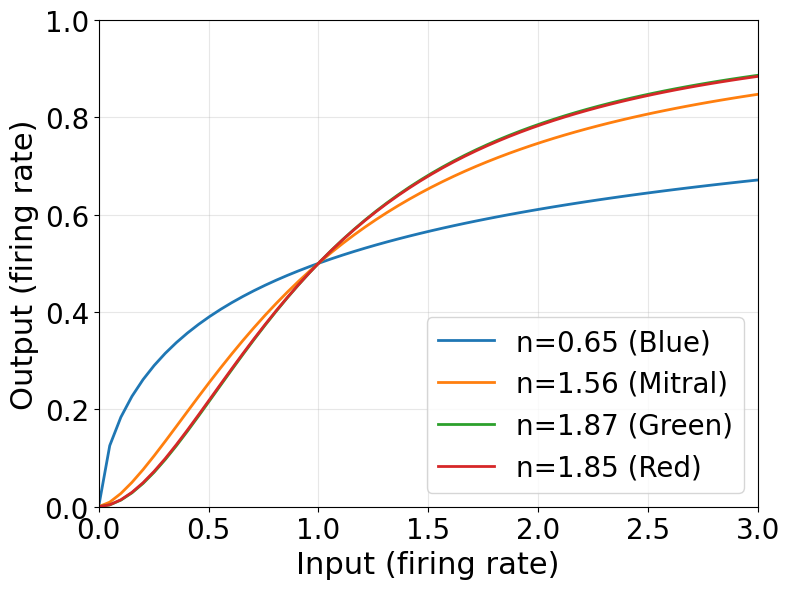

In [16]:
# Visualise the Naka-Rushton function
x_vals = jnp.linspace(0, 5, 100)
n_values = [n_b, n_y, n_g, n_r]
cell_labels = ['Blue', 'Mitral', 'Green', 'Red']

plt.figure(figsize=(8,6))
for n, cell in zip(n_values, cell_labels):
    y_vals = nr(x_vals, n=n)
    plt.plot(x_vals, y_vals, label=f'n={n:.2f} ({cell})', linewidth=2)

plt.xlabel('Input (firing rate)', fontsize=22)
plt.ylabel('Output (firing rate)', fontsize=22)
plt.grid(True, alpha=0.3)
plt.xlim(0, 3)
plt.ylim(0, 1)
plt.tick_params(axis='both', direction='out', labelsize=20)
plt.legend(fontsize=20)
plt.tight_layout()
plt.savefig(f'Figures_final/Naka_Rushton.eps')
plt.show()